# Task 4: Blind Source Separation using Independent Component Analysis

## Step 1: Import libraries and configure plotting

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import FastICA, PCA

plt.rcParams.update({"font.size": 9, "figure.dpi": 200})
results = {}

## Step 2: Load or generate data and fit the model

In [2]:
t = np.linspace(0, 1, 1000)
S = np.c_[np.sin(2 * np.pi * 5 * t), np.sign(np.sin(2 * np.pi * 3 * t))]   # sources, 1000 x 2
A = np.array([[1, 1], [0.5, 2.0]])                                           # mixing matrix
X4 = S @ A.T                                                                 # observations x = A s
S_ica = FastICA(n_components=2, whiten="unit-variance", random_state=0).fit_transform(X4)
S_pca = PCA(n_components=2).fit_transform(X4)                                # for comparison

## Step 3: Collect the assessment results

In [3]:
def match(est):
    """|corr| of each true source with its best-matching recovered component."""
    c = np.abs(np.corrcoef(S.T, est.T)[:2, 2:])
    return c, c.max(axis=1)


c_ica, best_ica = match(S_ica)
c_pca, best_pca = match(S_pca)
results["task4"] = {"ica_best_corr": best_ica.tolist(), "pca_best_corr": best_pca.tolist(),
                    "ica_corr": c_ica.tolist(), "pca_corr": c_pca.tolist()}

## Step 4: Display key numerical results

In [4]:
print("Best absolute correlations (sine, square):")
print("FastICA:", np.round(best_ica, 10))
print("PCA:    ", np.round(best_pca, 10))
print("FastICA correlation matrix:\n", np.round(c_ica, 8))
print("PCA correlation matrix:\n", np.round(c_pca, 8))

Best absolute correlations (sine, square):
FastICA: [0.99965066 0.99965066]
PCA:     [0.9591099 0.9591099]
FastICA correlation matrix:
 [[0.02643007 0.99965066]
 [0.99965066 0.02643007]]
PCA correlation matrix:
 [[0.28303391 0.9591099 ]
 [0.9591099  0.28303391]]


## Step 5: Show the main figure

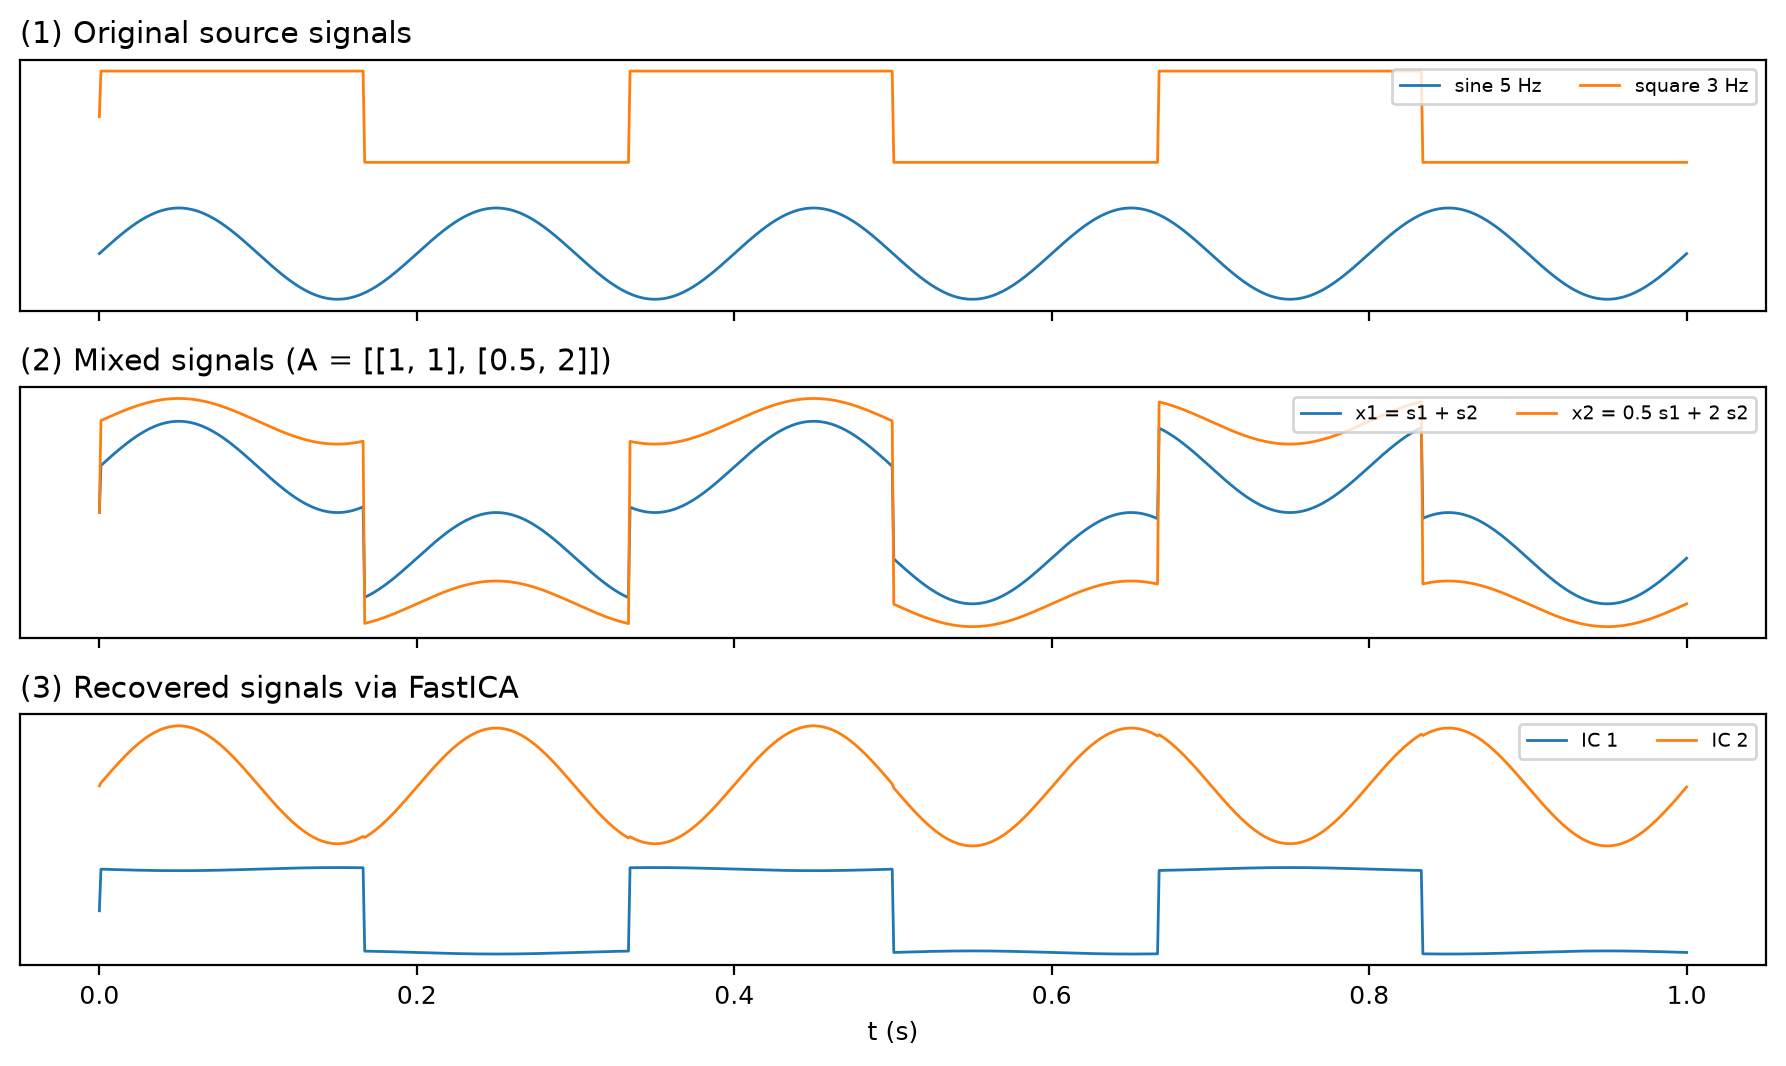

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(9, 5.4), sharex=True)
panels = [(S, ["sine 5 Hz", "square 3 Hz"], "(1) Original source signals"),
          (X4, ["x1 = s1 + s2", "x2 = 0.5 s1 + 2 s2"], "(2) Mixed signals (A = [[1, 1], [0.5, 2]])"),
          (S_ica, ["IC 1", "IC 2"], "(3) Recovered signals via FastICA")]
for ax, (sig, names, title) in zip(axes, panels):
    for j, (name, color) in enumerate(zip(names, ("tab:blue", "tab:orange"))):
        ax.plot(t, sig[:, j] + (0 if sig is X4 else 3 * j), color=color, lw=1, label=name)
    ax.set_title(title, loc="left")
    ax.legend(loc="upper right", fontsize=7, ncol=2)
    ax.set_yticks([])
axes[-1].set_xlabel("t (s)")
fig.tight_layout()
plt.show()

## Complete numeric results for reproducibility

In [6]:
print(json.dumps(results["task4"], sort_keys=True))

{"ica_best_corr": [0.9996506646308965, 0.9996506646308969], "ica_corr": [[0.026430071944784805, 0.9996506646308965], [0.9996506646308969, 0.026430071944785034]], "pca_best_corr": [0.9591099021805419, 0.9591099021805423], "pca_corr": [[0.28303391234838166, 0.9591099021805419], [0.9591099021805423, 0.28303391234838227]]}
